# 02 - Storage vs price

**Question:** does the amount of gas in storage, compared with what's normal for the time of year, explain the Henry Hub price?

The raw storage number on its own means little: 3,000 Bcf is a lot in April but low in November. Traders compare it with the **5-year average and range for the same week**. The gap is called the **surplus or deficit**:
- **Deficit (below normal):** the market is tight. Buyers worry about running short in winter, so prices rise.
- **Surplus (above normal):** there's plenty of gas, so prices fall.

This notebook uses the data saved by `01_data.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

storage = pd.read_csv(DATA_DIR / "storage_surprise.csv", index_col="period", parse_dates=["period", "report_date"])
prices = pd.read_csv(DATA_DIR / "prices_daily.csv", index_col="Date", parse_dates=True)

from style import BAND, BLUE, GRAY, INK, INK2, ORANGE, RED  # shared project chart style


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 1. Storage vs its 5-year normal
For every week, the code computes the average, minimum and maximum storage for the same week over the **previous** 5 years. Using only past years means each number is something a trader could have known at the time.

Two ways to measure the gap:
- **`deviation_bcf`:** the gap in Bcf.
- **`deviation_pct`:** the same gap as a % of normal. This is fairer across years, because total US storage use has grown over time.

In [2]:
levels = storage.pivot_table(index="year", columns="week", values="storage_bcf")
prior5 = levels.shift(1).rolling(5, min_periods=5)  # previous 5 years only

for name, table in {"avg5": prior5.mean(), "min5": prior5.min(), "max5": prior5.max()}.items():
    storage = storage.join(table.stack().rename(f"storage_{name}"), on=["year", "week"])

storage["deviation_bcf"] = storage["storage_bcf"] - storage["storage_avg5"]
storage["deviation_pct"] = storage["deviation_bcf"] / storage["storage_avg5"] * 100

# Henry Hub on the Friday each storage week ends (last available close if Friday was a holiday)
storage["henry_hub"] = prices["henry_hub"].asof(storage.index)

storage.to_csv(DATA_DIR / "storage_features.csv")
storage[["storage_bcf", "storage_avg5", "deviation_bcf", "deviation_pct", "henry_hub"]].dropna().tail()

,storage_bcf,storage_avg5,deviation_bcf,deviation_pct,henry_hub
period,,,,,
2026-09-25,3415,3387.6,27.4,0.808832,3.196
2026-10-02,3500,3478.0,22.0,0.632547,3.035
2026-10-09,3567,3569.4,-2.4,-0.067238,3.220
2026-10-16,3644,3645.0,-1.0,-0.027435,3.116
2026-10-23,3724,3725.4,-1.4,-0.037580,2.640


## 2. The seasonal chart
This is the standard chart on every gas desk. Storage fills from April to October (injection season) and empties from November to March (withdrawal season).

Where the current year sits inside the grey band tells you whether the market is tight or loose going into winter. Winter matters most, because a cold snap with low storage is what produces price spikes.

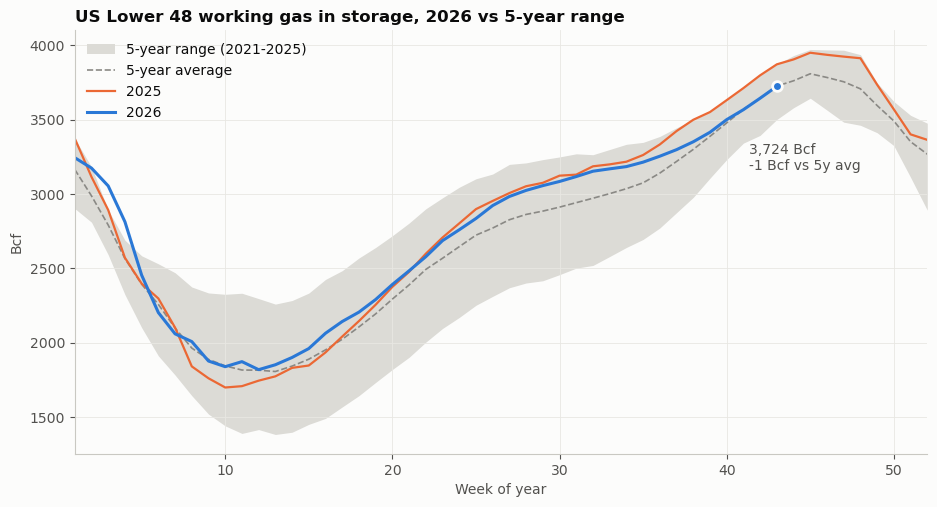

In [3]:
this_year = int(storage["year"].max())
hist = levels.loc[this_year - 5 : this_year - 1].drop(columns=53, errors="ignore")
cur = storage[storage["year"] == this_year].set_index("week")
prev = storage[storage["year"] == this_year - 1].set_index("week")

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.fill_between(hist.columns, hist.min(), hist.max(), color=BAND, lw=0,
                label=f"5-year range ({this_year - 5}-{this_year - 1})")
ax.plot(hist.columns, hist.mean(), color=GRAY, ls="--", lw=1.2, label="5-year average")
ax.plot(prev.index, prev["storage_bcf"], color=ORANGE, label=str(this_year - 1))
ax.plot(cur.index, cur["storage_bcf"], color=BLUE, lw=2.2, label=str(this_year))

last = cur.iloc[-1]
ax.plot(cur.index[-1], last["storage_bcf"], "o", color=BLUE, ms=7, mec="#fcfcfb", mew=2)
ax.annotate(f"{last['storage_bcf']:,.0f} Bcf\n{last['deviation_bcf']:+,.0f} Bcf vs 5y avg",
            (cur.index[-1], last["storage_bcf"]), xytext=(-20, -60), textcoords="offset points", color=INK2)

ax.set_title(f"US Lower 48 working gas in storage, {this_year} vs 5-year range")
ax.set_xlabel("Week of year")
ax.set_ylabel("Bcf")
ax.set_xlim(1, 52)
ax.legend(loc="upper left")
save(fig, "01_storage_seasonal")
plt.show()

## 3. Surplus/deficit vs price over time
The two series are in different units ($/MMBtu and Bcf), so they go on **separate panels with a shared time axis** rather than one chart with two y-axes. A chart with two y-axes lets you line the scales up however you like, which can make a relationship look stronger than it is.

**What to look for:** does price rise when the bottom panel is red (a deficit) and fall when it's blue (a surplus)?

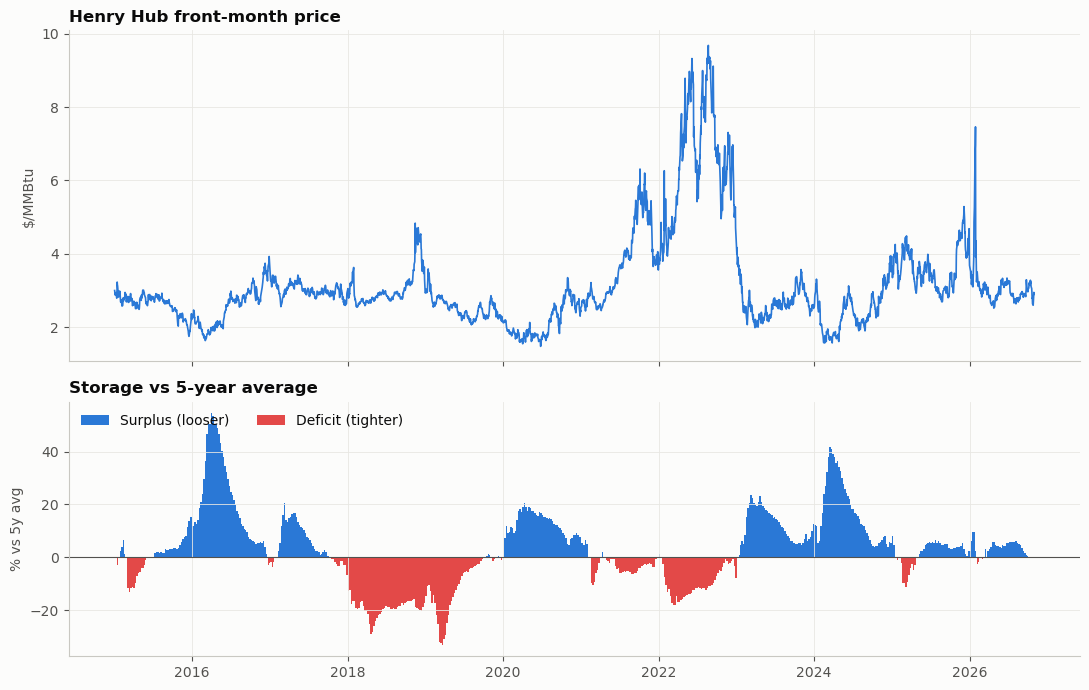

In [4]:
recent = storage.loc["2015":].dropna(subset=["deviation_pct"])
hh = prices["henry_hub"].loc["2015":]
dev = recent["deviation_pct"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax1.plot(hh.index, hh, color=BLUE, lw=1.2)
ax1.set_title("Henry Hub front-month price")
ax1.set_ylabel("$/MMBtu")

ax2.fill_between(dev.index, dev, 0, where=dev >= 0, color=BLUE, lw=0, step="mid", label="Surplus (looser)")
ax2.fill_between(dev.index, dev, 0, where=dev < 0, color=RED, lw=0, step="mid", label="Deficit (tighter)")
ax2.axhline(0, color=INK2, lw=0.8)
ax2.set_title("Storage vs 5-year average")
ax2.set_ylabel("% vs 5y avg")
ax2.legend(loc="upper left", ncol=2)
fig.tight_layout()
save(fig, "02_price_vs_storage_deviation")
plt.show()

## 4. How strong is the link?
Each dot below is one week: storage deviation against price.

There's a statistical trap here, the same one as in the Brent notebook. Price **levels** trend, so two unrelated trending series can look correlated. A more honest test uses **changes**: when the deficit grows over 4 weeks, does price rise over the same 4 weeks?

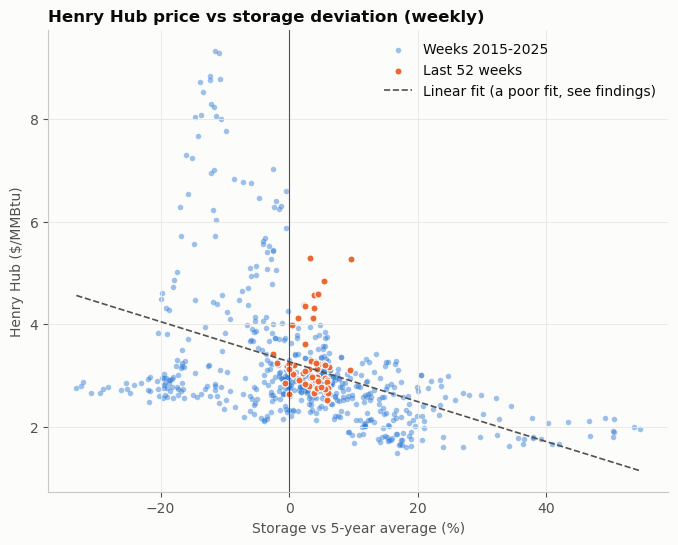

Correlation, levels:         -0.43
Correlation, 4-week changes: -0.28  (deviation change vs log price change)
Deviation -50% to -10%: median $2.95, 90th percentile $8.03  (114 weeks)
Deviation -10% to +10%: median $2.96, 90th percentile $4.37  (351 weeks)
Deviation +10% to +60%: median $2.18, 90th percentile $2.99  (150 weeks)


In [5]:
weekly = storage.loc["2015":, ["deviation_pct", "henry_hub"]].dropna()
last52 = weekly.iloc[-52:]

corr_levels = weekly["deviation_pct"].corr(weekly["henry_hub"])
chg = weekly.diff(4).dropna()  # 4-week changes, overlapping
corr_changes = chg["deviation_pct"].corr(np.log(weekly["henry_hub"]).diff(4).dropna())
slope, intercept = np.polyfit(weekly["deviation_pct"], weekly["henry_hub"], 1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(weekly["deviation_pct"], weekly["henry_hub"], s=16, color=BLUE, alpha=0.45, lw=0,
           label=f"Weeks 2015-{weekly.index[-53].year}")
ax.scatter(last52["deviation_pct"], last52["henry_hub"], s=26, color=ORANGE, ec="#fcfcfb", lw=0.8, label="Last 52 weeks")
xs = np.linspace(weekly["deviation_pct"].min(), weekly["deviation_pct"].max(), 50)
ax.plot(xs, intercept + slope * xs, color=INK2, lw=1.2, ls="--", label="Linear fit (a poor fit, see findings)")
ax.axvline(0, color=INK2, lw=0.8)
ax.set_title("Henry Hub price vs storage deviation (weekly)")
ax.set_xlabel("Storage vs 5-year average (%)")
ax.set_ylabel("Henry Hub ($/MMBtu)")
ax.legend(loc="upper right")
save(fig, "03_price_vs_deviation_scatter")
plt.show()

print(f"Correlation, levels:         {corr_levels:+.2f}")
print(f"Correlation, 4-week changes: {corr_changes:+.2f}  (deviation change vs log price change)")
for lo, hi in [(-50, -10), (-10, 10), (10, 60)]:
    bucket = weekly.loc[weekly["deviation_pct"].between(lo, hi, inclusive="left"), "henry_hub"]
    print(f"Deviation {lo:+}% to {hi:+}%: median ${bucket.median():.2f}, 90th percentile ${bucket.quantile(0.9):.2f}  ({len(bucket)} weeks)")

## 5. Gas vs oil in the same units
Brent is quoted per barrel and gas per MMBtu. One barrel of crude holds about **5.8 MMBtu** of energy, so dividing Brent by 5.8 puts both on the same energy basis and the same axis.

The gap shows how cheap US gas is compared with oil, per unit of energy. US gas is priced off US supply and demand, since a pipeline can't carry it out of the country. Only LNG export capacity links it to world prices, and that link is Phase 2.

The lower panel shows the rolling 1-year correlation of weekly returns: do they even move together?

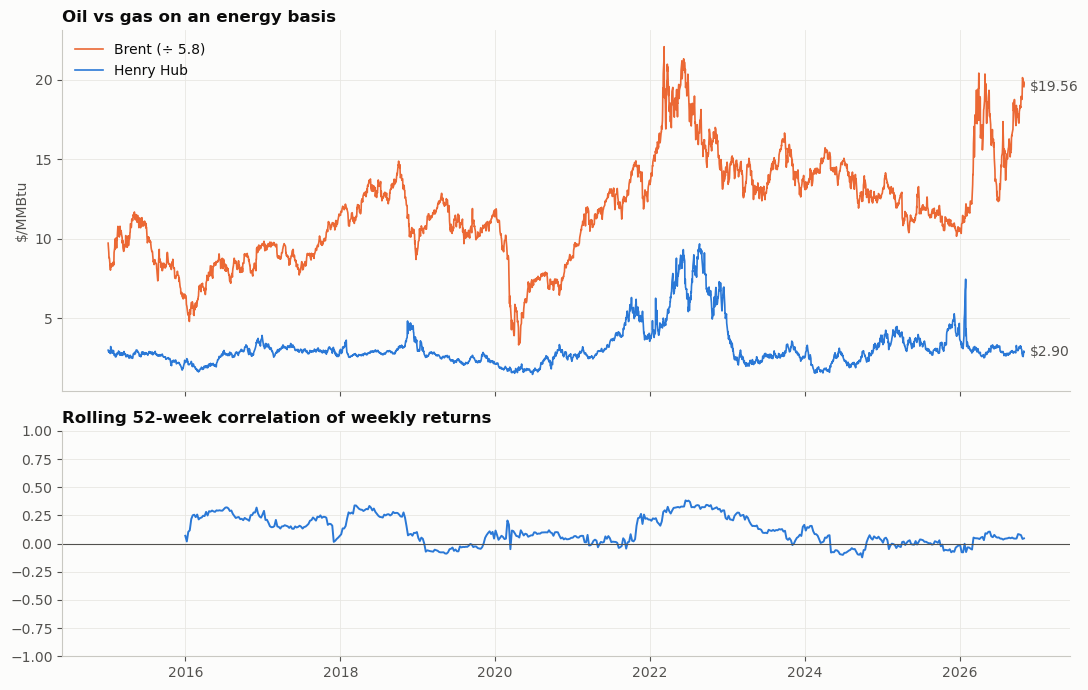

Brent is 6.7x the price of Henry Hub per MMBtu; average since 2015: 4.0x
Full-period correlation of weekly returns: +0.09


In [6]:
MMBTU_PER_BBL = 5.8
energy = prices.loc["2015":, ["henry_hub", "brent"]].dropna()
energy["brent_mmbtu"] = energy["brent"] / MMBTU_PER_BBL

wk = np.log(energy[["henry_hub", "brent"]].resample("W-FRI").last()).diff()
roll_corr = wk["henry_hub"].rolling(52).corr(wk["brent"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
ax1.plot(energy.index, energy["brent_mmbtu"], color=ORANGE, lw=1.2, label="Brent (÷ 5.8)")
ax1.plot(energy.index, energy["henry_hub"], color=BLUE, lw=1.2, label="Henry Hub")
for col, color in [("brent_mmbtu", ORANGE), ("henry_hub", BLUE)]:
    ax1.annotate(f"${energy[col].iloc[-1]:.2f}", (energy.index[-1], energy[col].iloc[-1]),
                 xytext=(4, 0), textcoords="offset points", va="center", color=INK2)
ax1.set_title("Oil vs gas on an energy basis")
ax1.set_ylabel("$/MMBtu")
ax1.legend(loc="upper left")

ax2.plot(roll_corr.index, roll_corr, color=BLUE, lw=1.4)
ax2.axhline(0, color=INK2, lw=0.8)
ax2.set_title("Rolling 52-week correlation of weekly returns")
ax2.set_ylim(-1, 1)
fig.tight_layout()
save(fig, "04_oil_vs_gas_energy_basis")
plt.show()

ratio = energy["brent_mmbtu"].iloc[-1] / energy["henry_hub"].iloc[-1]
print(f"Brent is {ratio:.1f}x the price of Henry Hub per MMBtu; "
      f"average since 2015: {(energy['brent_mmbtu'] / energy['henry_hub']).mean():.1f}x")
print(f"Full-period correlation of weekly returns: {wk['henry_hub'].corr(wk['brent']):+.2f}")

## Findings

**1. Storage explains price, but only partly, and not in a straight line.**
- Correlation on levels is about -0.43. On 4-week changes it's about -0.28, which is a weaker but more honest number.
- The relationship is **asymmetric**, which the bucket table shows:
  - **Surpluses** push price towards a floor of about $2. Below that, producers cut drilling.
  - **Deficits** don't give a steady higher price. They give a wider range of outcomes, including spikes, because a deficit only turns into a spike if something else goes wrong, like a cold winter or strong export demand.
- For trading: a deficit makes upside spikes possible but doesn't make them likely. That favours positions with limited downside over simple directional bets.

**2. The same storage gap doesn't always mean the same price.** Two clusters break the pattern:
- **2022:** price reached $6-9 with only a 10-15% deficit.
- **The last 52 weeks:** price ran higher than history at the same small surplus.

A likely explanation for both is demand from outside the US storage picture: the European gas crisis in 2022, and growing LNG export capacity since then. That's a hypothesis to test in Phase 2, not a proven fact.

**3. Storage is back to normal heading into winter (about -1 Bcf vs the 5-year average on 23 Oct 2026).** In September the market was injecting less than normal and the surplus disappeared. With storage at normal levels, **weather becomes the main driver** of winter prices.

**4. Oil and gas are separate markets.**
- Weekly returns barely move together: correlation is about +0.09, and the rolling correlation never exceeds about 0.4.
- Brent costs about 6.7 times as much as Henry Hub per unit of energy, against an average of about 4 times since 2015.
- For trading: holding both is closer to two independent bets than to doubling up on "energy".